# Лабораторная работа 1

## Постановка задачи

Самостоятельно написать код, реализующий искусственный нейрон с сигма-функцией
активации, и возможность строить на его основе многослойные сети. Код должен также
реализовывать градиентный спуск и обратное распространение ошибки.
На основе вашего кода:
1. Решить задачу классификации датаcета Iris одним нейроном.
2. Решить задачу классификации датаcета Iris одним нейросетью из 2 слоев по 10
нейронов в слое.
3. Отрисовать разделяющую линию для обеих моделей. Сравнить метрики
классификации.

## Программа

Accuracy 1 Neuron: 1.0
Accuracy 2x10 Net: 1.0


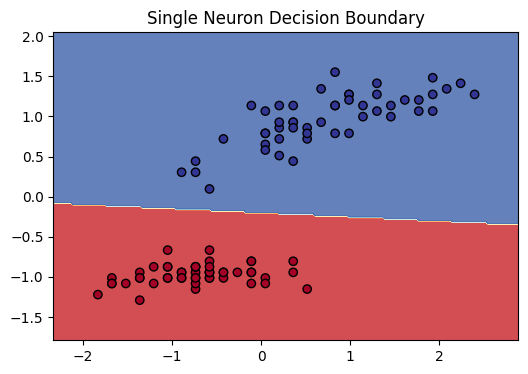

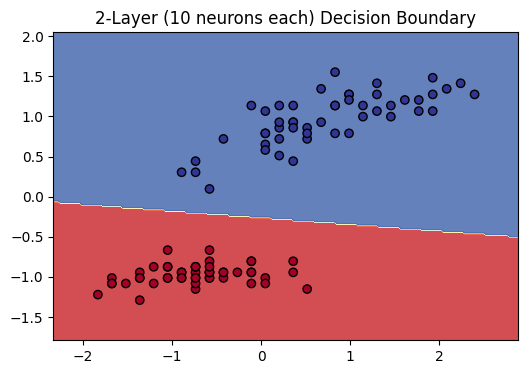

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.metrics import accuracy_score

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_deriv(a):
    return a * (1 - a)

class Layer:
    def __init__(self, input_size, output_size):
        self.W = np.random.randn(input_size, output_size) * 0.1
        self.b = np.zeros((1, output_size))

    def forward(self, X):
        self.X = X
        self.A = sigmoid(np.dot(X, self.W) + self.b)
        return self.A

class Network:
    def __init__(self, layers_config):
        self.layers = []
        for i in range(len(layers_config) - 1):
            self.layers.append(Layer(layers_config[i], layers_config[i+1]))

    def forward(self, X):
        A = X
        for layer in self.layers:
            A = layer.forward(A)
        return A

    def backward(self, y, lr):
        m = y.shape[0]
        A_final = self.layers[-1].A
        dZ = A_final - y

        for i in reversed(range(len(self.layers))):
            layer = self.layers[i]
            prev_A = self.layers[i-1].A if i > 0 else layer.X

            dW = np.dot(prev_A.T, dZ) / m
            db = np.sum(dZ, axis=0, keepdims=True) / m

            if i > 0:
                dA_prev = np.dot(dZ, layer.W.T)
                dZ = dA_prev * sigmoid_deriv(prev_A)

            layer.W -= lr * dW
            layer.b -= lr * db

    def fit(self, X, y, epochs=5000, lr=0.1):
        for _ in range(epochs):
            self.forward(X)
            self.backward(y, lr)

    def predict(self, X):
        return (self.forward(X) > 0.5).astype(int)


iris = datasets.load_iris()
X = iris.data[iris.target != 2][:, [0, 2]]
y = iris.target[iris.target != 2].reshape(-1, 1)

X = (X - X.mean(axis=0)) / X.std(axis=0)


neuron = Network([2, 1])
neuron.fit(X, y, epochs=2000, lr=0.5)

net = Network([2, 10, 10, 1])
net.fit(X, y, epochs=5000, lr=0.5)

y_pred_neuron = neuron.predict(X)
y_pred_net = net.predict(X)

print("Accuracy 1 Neuron:", accuracy_score(y, y_pred_neuron))
print("Accuracy 2x10 Net:", accuracy_score(y, y_pred_net))

def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(6,4))
    plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), edgecolors='k', cmap=plt.cm.RdYlBu)
    plt.title(title)
    plt.show()

plot_boundary(neuron, X, y, "Single Neuron Decision Boundary")
plot_boundary(net, X, y, "2-Layer (10 neurons each) Decision Boundary")

## Вывод



В ходе лабораторной работы были реализованы с нуля и протестированы две архитектуры нейронных сетей: одиночный нейрон и многослойная сеть (2 скрытых слоя по 10 нейронов). Алгоритмы прямого и обратного распространения ошибки, а также градиентный спуск были написаны без использования сторонних ML-фреймворков.

Сравнение метрик и визуальный анализ:

Обе архитектуры достигли максимальной точности классификации (Accuracy = 1.0). Это обусловлено тем, что выбранные признаки из датасета Iris образуют два идеально линейно разделимых класса — на графиках видно, что группы точек четко разнесены в пространстве и не пересекаются.

Сравнивая визуализации разделяющих поверхностей (Decision Boundary), можно заметить, что обе границы имеют строгий линейный характер и визуально идентичны.

Обоснование результатов:
Для одиночного нейрона прямая разделяющая линия — это единственно возможный результат, так как математически он представляет собой простейший линейный классификатор.

Многослойная сеть (2x10), напротив, обладает высокой репрезентативной емкостью и способна аппроксимировать сложные нелинейные функции и строить изогнутые границы. Однако алгоритм градиентного спуска стремится минимизировать функцию потерь кратчайшим путем. Поскольку классы легко разделяются прямой, сеть нашла простейший глобальный минимум весов, при котором граница принятия решений выродилась в обычную линию.